# 07. An?lisis de Monitoreo, Deriva, Negocio y Reentrenamiento ? OralSolutions

Eval?a lote por lote las m?tricas de **datos (PSI, KS, Chi?)**, **modelo (PR-AUC)**, **alertas calibradas**, **resultado de negocio en USD** frente a las l?neas base y el **ciclo de reentrenamiento controlado (`v7` vs. `v9`)**.


In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

df_mon = pd.read_csv(ROOT / "docs" / "monitoreo.csv")
df_alertas = pd.read_csv(ROOT / "docs" / "alertas.csv")
df_reent = pd.read_csv(ROOT / "docs" / "reentrenamientos.csv")

cols = ["lote_id", "tipo_lote", "n_sesiones", "pr_auc", "psi_max", "feature_psi_max", "p_valor_top_deriva", "diagnostico", "n_alertas"]
df_mon[cols]


,lote_id,tipo_lote,n_sesiones,pr_auc,psi_max,feature_psi_max,p_valor_top_deriva,diagnostico,n_alertas
0,L01,produccion_real,104,0.98227,0.21483,edad_en_atencion,0.102193,Normal (sin deriva),0
1,L02,produccion_real,104,0.98438,0.07417,ritmo_dias_por_sesion,0.472509,Normal (sin deriva),0
2,L03,produccion_real,103,0.97430,0.21721,edad_en_atencion,0.242423,Normal (sin deriva),0
3,L04,produccion_real,103,0.97066,0.11206,edad_en_atencion,0.296259,Normal (sin deriva),0
4,L05,produccion_real,103,0.98356,0.27466,edad_en_atencion,0.074695,Normal (sin deriva),0
5,L06,produccion_real,103,0.97481,0.06223,inasistencias_previas,1.000000,Normal (sin deriva),0
6,L07,produccion_real,103,1.00000,0.10279,codigo_procedimiento,0.054890,Normal (sin deriva),0
7,L08,produccion_real,103,0.99119,0.10895,edad_en_atencion,0.840001,Normal (sin deriva),0
8,L09_deriva_datos,deriva_datos_inducida,103,0.98312,13.45951,ritmo_dias_por_sesion,0.000000,Deriva de datos sin impacto,1
9,L10_deriva_conceptual,deriva_conceptual_inducida,103,0.54504,0.10895,edad_en_atencion,0.840001,Deriva conceptual,1


### 1. Evoluci?n lote por lote: Deriva conceptual (`PR-AUC`) vs. Deriva de datos (`PSI`)
Umbrales calibrados por simulaci?n para eliminar falsas alarmas en `L01`?`L08`: **PSI > 0.30** y **PR-AUC < 0.960**.


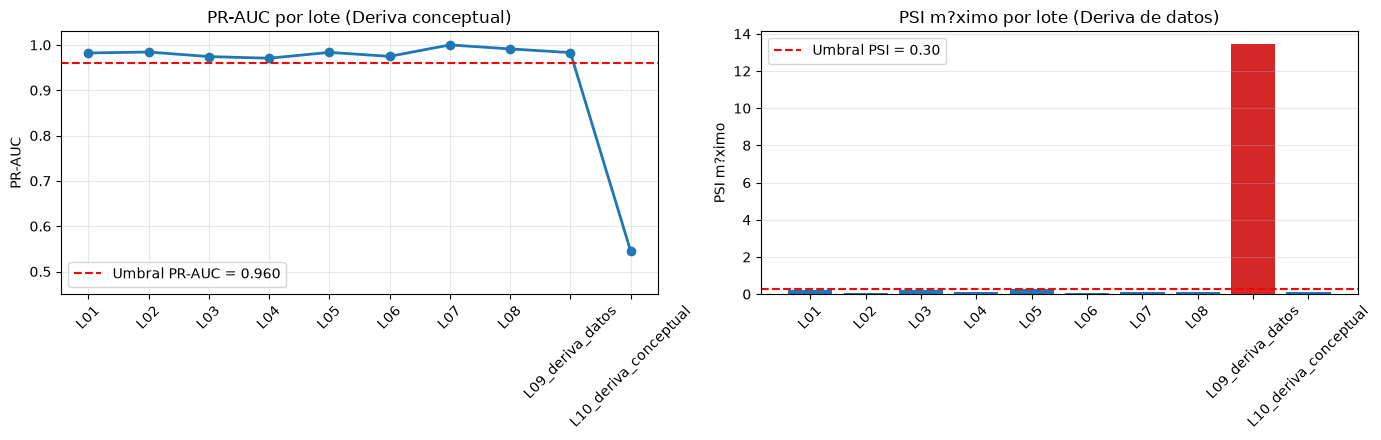

=== Alertas registradas (docs/alertas.csv) ===


,timestamp,lote_id,metrica,valor_observado,umbral,ventana,severidad,destinatario,accion
0,2026-11-19T16:11:23.591382+00:00,L09_deriva_datos,PSI de ritmo_dias_por_sesion,13.45951,> 0.3,1 lote,Alta,Equipo de Datos / MLOps,"Revisar fuente de datos, confirmar impacto en ..."
1,2026-11-19T16:11:24.642601+00:00,L10_deriva_conceptual,PR-AUC del lote (deriva conceptual/desempeño),0.54504,< 0.96 (calibrado por simulación),1 lote etiquetado,Crítica,Equipo de Datos + Gerencia Clínica,Disparar flujo de reentrenamiento en Kestra y ...


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(df_mon["lote_id"], df_mon["pr_auc"], marker="o", linewidth=2, color="#1f77b4")
axes[0].axhline(0.960, color="red", linestyle="--", label="Umbral PR-AUC = 0.960")
axes[0].set_title("PR-AUC por lote (Deriva conceptual)")
axes[0].set_ylabel("PR-AUC")
axes[0].set_ylim(0.45, 1.03)
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()
axes[0].grid(alpha=0.3)

colores = ["#d62728" if v > 0.30 else "#1f77b4" for v in df_mon["psi_max"]]
axes[1].bar(df_mon["lote_id"], df_mon["psi_max"], color=colores)
axes[1].axhline(0.30, color="red", linestyle="--", label="Umbral PSI = 0.30")
axes[1].set_title("PSI m?ximo por lote (Deriva de datos)")
axes[1].set_ylabel("PSI m?ximo")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

print("=== Alertas registradas (docs/alertas.csv) ===")
df_alertas


### 2. Resultado de negocio lote por lote (`L01`?`L08` producci?n real)
Comparaci?n de costo de errores (`FN = $120`, `FP = $3`) y balance neto frente a la regla operativa (`Regla_1_Sesion`) y no hacer nada.


,Estrategia,Costo total errores (USD),Balance neto (USD)
0,Modelo @champion (u=0.01),1518.0,18294.0
1,Regla operativa (1 sesi?n restante),5880.0,12294.0
2,Llamar a todos,933.0,NaN
3,No hacer nada,61800.0,NaN


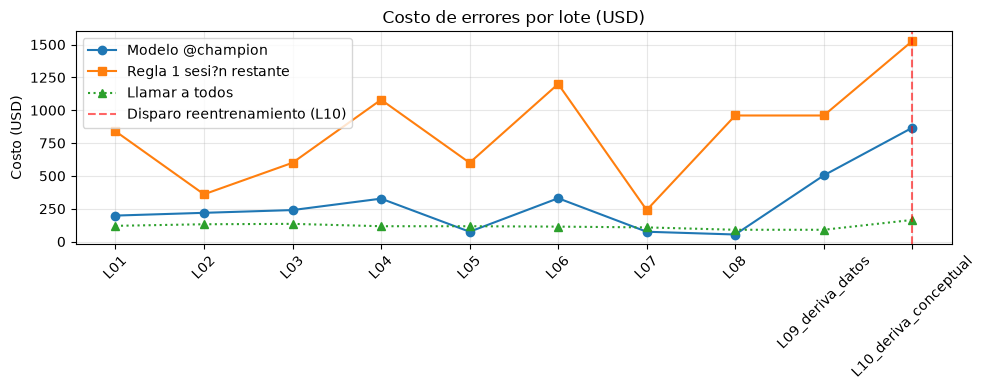

In [3]:
df_real = df_mon[df_mon["tipo_lote"] == "produccion_real"]

resumen_negocio = pd.DataFrame({
    "Estrategia": ["Modelo @champion (u=0.01)", "Regla operativa (1 sesi?n restante)", "Llamar a todos", "No hacer nada"],
    "Costo total errores (USD)": [
        df_real["costo_modelo_usd"].sum(),
        df_real["costo_regla_1_sesion_usd"].sum(),
        df_real["costo_llamar_todos_usd"].sum(),
        df_real["costo_no_hacer_nada_usd"].sum(),
    ],
    "Balance neto (USD)": [
        df_real["balance_modelo_usd"].sum(),
        df_real["balance_regla_1_sesion_usd"].sum(),
        None,
        None,
    ],
})
display(resumen_negocio)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df_mon["lote_id"], df_mon["costo_modelo_usd"], marker="o", label="Modelo @champion")
ax.plot(df_mon["lote_id"], df_mon["costo_regla_1_sesion_usd"], marker="s", label="Regla 1 sesi?n restante")
ax.plot(df_mon["lote_id"], df_mon["costo_llamar_todos_usd"], marker="^", linestyle=":", label="Llamar a todos")
ax.axvline("L10_deriva_conceptual", color="red", linestyle="--", alpha=0.6, label="Disparo reentrenamiento (L10)")
ax.set_title("Costo de errores por lote (USD)")
ax.set_ylabel("Costo (USD)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 3. Evidencia del ciclo de reentrenamiento controlado (`v7` vs. `v9`)


In [4]:
ruta_reent = ROOT / "monitoreo" / "ultimo_reentrenamiento.json"
if ruta_reent.exists():
    evidencia = json.loads(ruta_reent.read_text(encoding="utf-8"))
    print(json.dumps(evidencia, indent=2, ensure_ascii=False))
df_reent


{
  "motivo_disparo": "Alerta critica de deriva conceptual en L10_deriva_conceptual (PR-AUC < 0.960)",
  "ventana_entrenamiento": "historico (1551) + L01-L08 (826) = 2377 filas",
  "lote_evaluacion": "L10_deriva_conceptual",
  "champion_actual": {
    "version": "7",
    "run_id": "169e8821e2c54761bf602b21f86aec93",
    "pr_auc": 0.61267,
    "recall": 0.875,
    "precision": 0.4615,
    "costo_errores_usd": 867.0,
    "balance_neto_usd": 771.0,
    "FP": 49,
    "FN": 6
  },
  "challenger_nuevo": {
    "version": "9",
    "run_id": "ee684c683fc04b54845826bc76ce3b32",
    "pr_auc": 0.58472,
    "recall": 0.9375,
    "precision": 0.4592,
    "costo_errores_usd": 519.0,
    "balance_neto_usd": 1236.0,
    "FP": 53,
    "FN": 3
  },
  "cumple_regla_promocion": false,
  "decision_humana": "rechazar",
  "motivo_decision": "Rechazado tras revision humana: la deriva conceptual de L10 requiere datos etiquetados bajo el nuevo comportamiento antes de promover",
  "promovido_a_champion": false
}


,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.pr_auc_challenger_eval,metrics.pr_auc_champion_eval,metrics.costo_challenger_usd,metrics.balance_champion_usd,...,tags.lote_evaluacion,tags.mlflow.user,tags.mlflow.runName,tags.motivo_decision,tags.cumple_regla_promocion,tags.mlflow.source.name,tags.familia,tags.git_commit,tags.candidato,tags.mlflow.parentRunId
0,ee684c683fc04b54845826bc76ce3b32,2,FINISHED,mlflow-artifacts:/2/ee684c683fc04b54845826bc76...,2026-11-19 16:31:13.925+00:00,2026-11-19 16:31:24.390+00:00,0.58472,0.61267,519.0,771.0,...,L10_deriva_conceptual,ANDRES,REENTRENAMIENTO_L10_deriva_conceptual,Rechazado tras revision humana: la deriva conc...,False,modelado/reentrenar.py,NaN,NaN,NaN,NaN
